# SIMKO — Pelatihan Prediksi ETA / ETD (Kompleks)

**Data:** `notebooks/data/` dari `generate_training_data.py` — 42 Lanud Kodau I/II/III GPS nyata, 30 tail TNI AU, 5000 misi + katalog 678 rute VFR.

**Tujuan:** prediksi **ETE (Estimated Time En-route)** → `ETA = ETD + ETE`. Bukan random: `ETE = (haversine / GS * 60) * severity + taxi`, `GS = cruise - 0.35*avg_wind`.

**Cakupan notebook:** EDA penuh → feature engineering → baseline 6 model → CV 5-fold → tuning (GridSearch HistGradientBoosting) → residual per tipe/jarak/kodau → ETA end-to-end → delay classifier → bottleneck → export joblib untuk `eta_prediction_model.py`.

```bash
./backend/venv/Scripts/python.exe notebooks/generate_training_data.py
./backend/venv/Scripts/jupyter.exe notebook notebooks/eta_training.ipynb
```
Pakai venv python (global tidak ada pandas/sklearn). `matplotlib/seaborn` sudah ada.

## 0. Setup

In [7]:
import pathlib, math, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
import joblib

DATA = pathlib.Path("data")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 80)

## 1. Load data

In [8]:
dim_ab = pd.read_csv(DATA / "dim_airbase.csv")
dim_ac = pd.read_csv(DATA / "dim_aircraft.csv")
dim_maint = pd.read_csv(DATA / "dim_maintenance_status.csv")
catalog = pd.read_csv(DATA / "route_ete_catalog.csv")
df = pd.read_csv(DATA / "flight_missions_train.csv")
df_full = pd.read_csv(DATA / "flight_missions_full.csv")
bn = pd.read_csv(DATA / "bottleneck_train.csv")

for c in ["etd","atd","eta_predicted","ata"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
    df_full[c] = pd.to_datetime(df_full[c], errors="coerce")
print(f"dim_airbase {dim_ab.shape} | dim_aircraft {dim_ac.shape} | catalog {catalog.shape}")
print(f"train {df.shape} | full {df_full.shape} | bottleneck {bn.shape}")
print("train cols:", list(df.columns))
df[["tail_number","type_key","origin_code","dest_code","origin_kodau","dest_kodau","distance_km","cruise_speed_kmh","avg_wind_kmh","weather_severity","predicted_duration_minutes","actual_duration_minutes","delay_minutes"]].head(8)

dim_airbase (42, 15) | dim_aircraft (30, 12) | catalog (678, 23)
train (5000, 53) | full (5000, 53) | bottleneck (800, 6)
train cols: ['mission_id', 'callsign', 'tail_number', 'aircraft_id', 'aircraft_type', 'type_key', 'squadron', 'mission_type', 'origin_id', 'origin_icao', 'origin_code', 'origin_name', 'origin_kodau', 'origin_tipe', 'origin_lat', 'origin_lon', 'dest_id', 'dest_icao', 'dest_code', 'dest_name', 'dest_kodau', 'dest_tipe', 'dest_lat', 'dest_lon', 'distance_km', 'cruise_speed_kmh', 'ground_speed_kmh', 'taxi_min', 'etd', 'atd', 'eta_predicted', 'ata', 'predicted_duration_minutes', 'actual_duration_minutes', 'delay_minutes', 'origin_weather_code', 'origin_weather', 'origin_temp_c', 'origin_wind_kmh', 'dest_weather_code', 'dest_weather', 'dest_temp_c', 'dest_wind_kmh', 'avg_wind_kmh', 'weather_severity', 'avtur_consumed_liters', 'status', 'year', 'quarter', 'month', 'day', 'hour', 'weekday']


,tail_number,type_key,origin_code,dest_code,origin_kodau,dest_kodau,distance_km,cruise_speed_kmh,avg_wind_kmh,weather_severity,predicted_duration_minutes,actual_duration_minutes,delay_minutes
0,TS-1603,f-16,IWJ,IGR,Kodau II,Kodau II,429.7,850,16.5,1.03,37.5,37.5,5.0
1,TT-3104,tucano,ABD,IGR,Kodau II,Kodau II,284.9,480,10.5,1.00,40.9,40.9,5.0
2,TS-1610,f-16,RSN,ABD,Kodau I,Kodau II,1559.0,850,9.2,1.03,119.8,119.8,5.0
3,TT-5003,t-50i,IGR,ELT,Kodau II,Kodau II,946.0,750,16.9,1.08,88.4,88.4,5.0
4,TT-3104,tucano,ABD,IGR,Kodau II,Kodau II,284.9,480,16.5,1.08,43.9,43.9,5.0
5,TT-5003,t-50i,IWJ,HLO,Kodau II,Kodau II,1276.8,750,9.8,1.00,108.6,108.6,5.0
6,TS-2702,sukhoi,HND,SSR,Kodau II,Kodau I,2182.1,900,14.9,1.08,165.0,165.0,5.0
7,TT-5003,t-50i,IWJ,MUL,Kodau II,Kodau II,151.5,750,10.2,1.00,18.2,18.2,5.0


In [9]:
# sanity: ada NaN? tipe unik?
print(df[["distance_km","cruise_speed_kmh","avg_wind_kmh","weather_severity","actual_duration_minutes"]].isna().sum().to_string())
print("\ntype_key:", df["type_key"].value_counts().to_dict())
print("kodau flow top 8:", (df["origin_kodau"]+" → "+df["dest_kodau"]).value_counts().head(8).to_dict())
print("origins:", sorted(df["origin_code"].unique())[:18])
print("dests:", sorted(df["dest_code"].unique()))
dim_ab.groupby("kodau").size()

distance_km                0
cruise_speed_kmh           0
avg_wind_kmh               0
weather_severity           0
actual_duration_minutes    0

type_key: {'f-16': 1549, 'sukhoi': 768, 'tucano': 755, 'c-130': 753, 'boeing': 598, 't-50i': 577}
kodau flow top 8: {'Kodau II → Kodau II': 2066, 'Kodau II → Kodau I': 1141, 'Kodau I → Kodau I': 854, 'Kodau I → Kodau II': 519, 'Kodau II → Kodau III': 200, 'Kodau I → Kodau III': 98, 'Kodau III → Kodau III': 68, 'Kodau III → Kodau II': 40}
origins: ['ABD', 'ADI', 'ASM', 'ATS', 'DMB', 'ELT', 'HLM', 'HLO', 'HND', 'IGR', 'IWJ', 'MNH', 'RSN', 'SDM', 'SLP', 'SPO', 'SRR', 'TAR']
dests: ['ABD', 'ADI', 'ASM', 'ATS', 'DMB', 'DMT', 'ELT', 'HAS', 'HHD', 'HLM', 'HLO', 'HND', 'HNDM', 'HSN', 'IGR', 'ISK', 'IWJ', 'JAD', 'JBS', 'LWM', 'MMS', 'MNH', 'MUL', 'PBY', 'PTM', 'RHF', 'RSA', 'RSN', 'SDM', 'SGS', 'SIM', 'SJN', 'SLP', 'SMH', 'SPO', 'SRR', 'SSR', 'SWD', 'TAR', 'WRD', 'YKP', 'ZAM']


kodau
Kodau I      20
Kodau II     15
Kodau III     7
dtype: int64

## 2. Dimensi Lanud (42) — runway & kapasitas

In [10]:
dim_ab.sort_values(["kodau","tipe","name"])[["code","name","kodau","tipe","icao","runway_m","elev_m","avtur_capacity_liters","apron_capacity","status"]].head(12)


,code,name,kodau,tipe,icao,runway_m,elev_m,avtur_capacity_liters,apron_capacity,status
1,ATS,Lanud Atang Sendjaja,Kodau I,A,WIAJ,1400,164,180000,12,optimal
0,HLM,Lanud Halim Perdanakusuma,Kodau I,A,WIHH,3000,25,1200000,30,optimal
3,RSN,Lanud Roesmin Nurjadin,Kodau I,A,WIBB,2600,31,750000,18,optimal
4,SPO,Lanud Supadio,Kodau I,A,WIOO,2250,3,600000,16,optimal
2,SDM,Lanud Suryadarma,Kodau I,A,WIHK,1600,110,220000,14,optimal
6,HSN,Lanud Husein Sastranegara,Kodau I,B,WICC,2249,743,400000,12,optimal
5,RSA,Lanud Raden Sadjad,Kodau I,B,WION,2560,2,350000,10,warning
10,RHF,Lanud Raja Haji Fisabilillah,Kodau I,B,WIDN,2250,16,300000,10,optimal
7,SWD,Lanud Soewondo,Kodau I,B,WIMK,2900,28,450000,14,optimal
11,SMH,Lanud Sri Mulyono Herlambang,Kodau I,B,WIPP,3000,11,480000,14,optimal


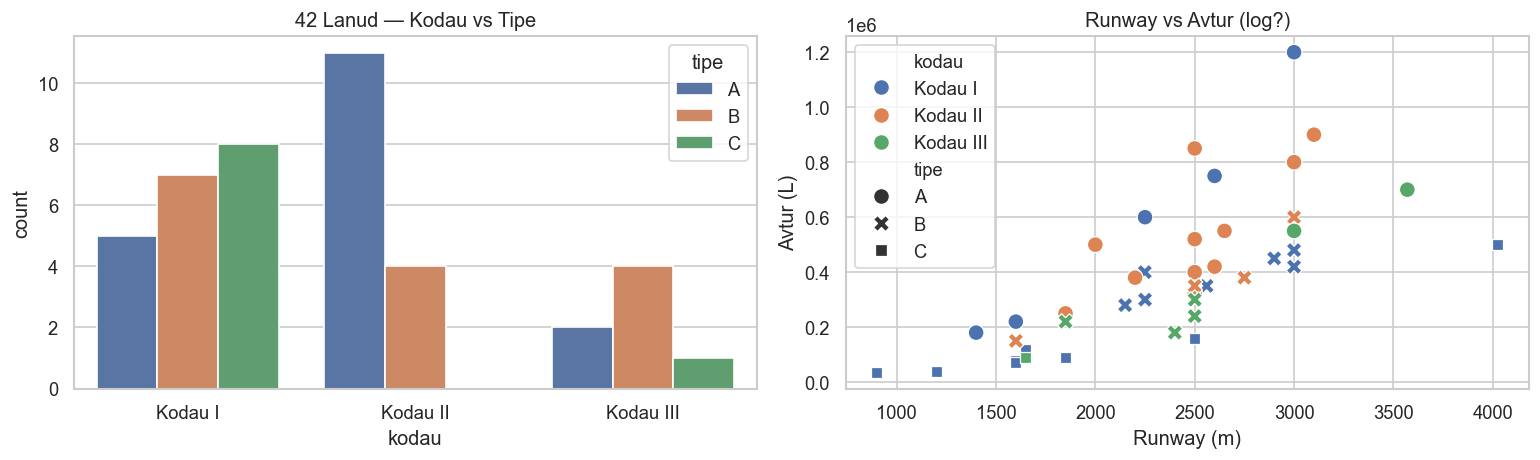

,runway_m,elev_m
count,42.0,42.0
mean,2357.2,85.5
std,640.4,142.7
min,900.0,2.0
25%,1850.0,11.2
50%,2500.0,34.5
75%,2725.0,102.8
max,4025.0,743.0


In [11]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
sns.countplot(data=dim_ab, x="kodau", hue="tipe", ax=ax[0]); ax[0].set_title("42 Lanud — Kodau vs Tipe")
sns.scatterplot(data=dim_ab, x="runway_m", y="avtur_capacity_liters", hue="kodau", style="tipe", s=90, ax=ax[1])
ax[1].set_title("Runway vs Avtur (log?)"); ax[1].set_xlabel("Runway (m)"); ax[1].set_ylabel("Avtur (L)")
plt.tight_layout(); plt.show()
dim_ab[["code","runway_m","elev_m"]].describe().round(1)

## 3. Katalog VFR — fisika ETE deterministik (validasi haversine)

In [12]:
def haversine_km(lat1, lon1, lat2, lon2):
    r=6371.0
    import math as _m
    p1,p2=_m.radians(lat1),_m.radians(lat2)
    dphi=_m.radians(lat2-lat1); dl=_m.radians(lon2-lon1)
    a=_m.sin(dphi/2)**2+_m.cos(p1)*_m.cos(p2)*_m.sin(dl/2)**2
    return 2*r*_m.asin(_m.sqrt(a))

m_ab = dim_ab.set_index("code")
checks=[("HLM","RSN"),("HLM","HND"),("IWJ","RSA"),("HND","TAR"),("HLM","MNH"),("ABD","IWJ"),("RSN","RSA"),("HND","SLP")]
for o,d in checks:
    a=m_ab.loc[o]; b=m_ab.loc[d]
    dist=haversine_km(float(a.lat),float(a.lon),float(b.lat),float(b.lon))
    rows=catalog[(catalog.origin_code==o)&(catalog.dest_code==d)]
    tag=f"cat {rows.iloc[0].distance_km} ETE {rows.iloc[0].ete_minutes}m {rows.iloc[0].tail_number}" if len(rows) else "— tidak di katalog (di luar MAX_RANGE/runway)"
    print(f"{o}-{d}: haversine {dist:.1f} km  {tag}")

# rumus ETE = (dist/GS*60)*severity+taxi harus match katalog (baseline VFR severity 1.0 wind 10)
gs = (catalog.cruise_speed_kmh - 0.35*catalog.avg_wind_kmh).clip(lower=catalog.cruise_speed_kmh*0.82)
pred = (catalog.distance_km/gs)*60*catalog.weather_severity + catalog.taxi_min
err=(pred.round(1)-catalog.ete_minutes).abs()
print(f"\nkatalog ETE vs rumus: max abs {err.max():.2f} min — rows >0.11 = {(err>0.11).sum()}")
catalog[["tail_number","type_key","origin_code","dest_code","distance_km","cruise_speed_kmh","ete_minutes","eta_example"]].head(6)

HLM-RSN: haversine 961.8 km  cat 961.8 ETE 119.6m A-1339
HLM-HND: haversine 1407.5 km  cat 1407.5 ETE 169.4m A-1339
IWJ-RSA: haversine 1325.3 km  cat 1325.3 ETE 99.9m TS-1601
HND-TAR: haversine 958.6 km  cat 958.6 ETE 71.2m TS-2701
HLM-MNH: haversine 3289.5 km  cat 3289.5 ETE 379.9m A-1339
ABD-IWJ: haversine 145.2 km  cat 145.2 ETE 23.3m TT-3101
RSN-RSA: haversine 861.4 km  cat 861.4 ETE 67.1m TS-1610
HND-SLP: haversine 2341.8 km  cat 2341.8 ETE 163.7m TS-2701

katalog ETE vs rumus: max abs 0.10 min — rows >0.11 = 0


,tail_number,type_key,origin_code,dest_code,distance_km,cruise_speed_kmh,ete_minutes,eta_example
0,TS-1601,f-16,IWJ,HLM,523.4,850,43.1,2026-06-01 07:43:06
1,TS-1601,f-16,IWJ,RSN,1426.0,850,107.1,2026-06-01 08:47:06
2,TS-1601,f-16,IWJ,SPO,860.4,850,67.0,2026-06-01 08:07:00
3,TS-1601,f-16,IWJ,RSA,1325.3,850,99.9,2026-06-01 08:39:54
4,TS-1601,f-16,IWJ,HSN,432.9,850,36.7,2026-06-01 07:36:42
5,TS-1601,f-16,IWJ,SSR,1438.8,850,108.0,2026-06-01 08:48:00


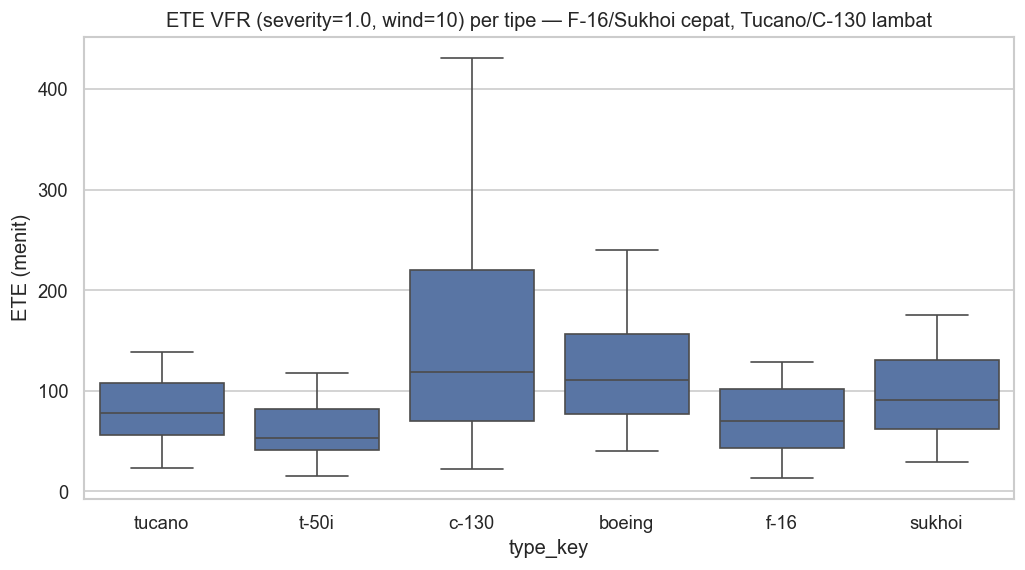

,count,mean,median,min,max
type_key,,,,,
boeing,87,118.5,110.9,39.9,240.2
c-130,152,161.1,119.1,22.0,431.3
f-16,160,70.9,70.4,13.9,128.5
sukhoi,120,95.3,90.9,29.5,175.0
t-50i,75,63.7,53.6,15.0,118.0
tucano,84,81.5,77.9,23.3,138.2


In [13]:
# distribusi ETE katalog per tipe (harus berbeda karena cruise berbeda)
plt.figure(figsize=(10,5))
sns.boxplot(data=catalog, x="type_key", y="ete_minutes", order=["tucano","t-50i","c-130","boeing","f-16","sukhoi"])
plt.title("ETE VFR (severity=1.0, wind=10) per tipe — F-16/Sukhoi cepat, Tucano/C-130 lambat")
plt.ylabel("ETE (menit)"); plt.show()
catalog.groupby("type_key")["ete_minutes"].agg(["count","mean","median","min","max"]).round(1)

## 4. EDA misi historis (5000)

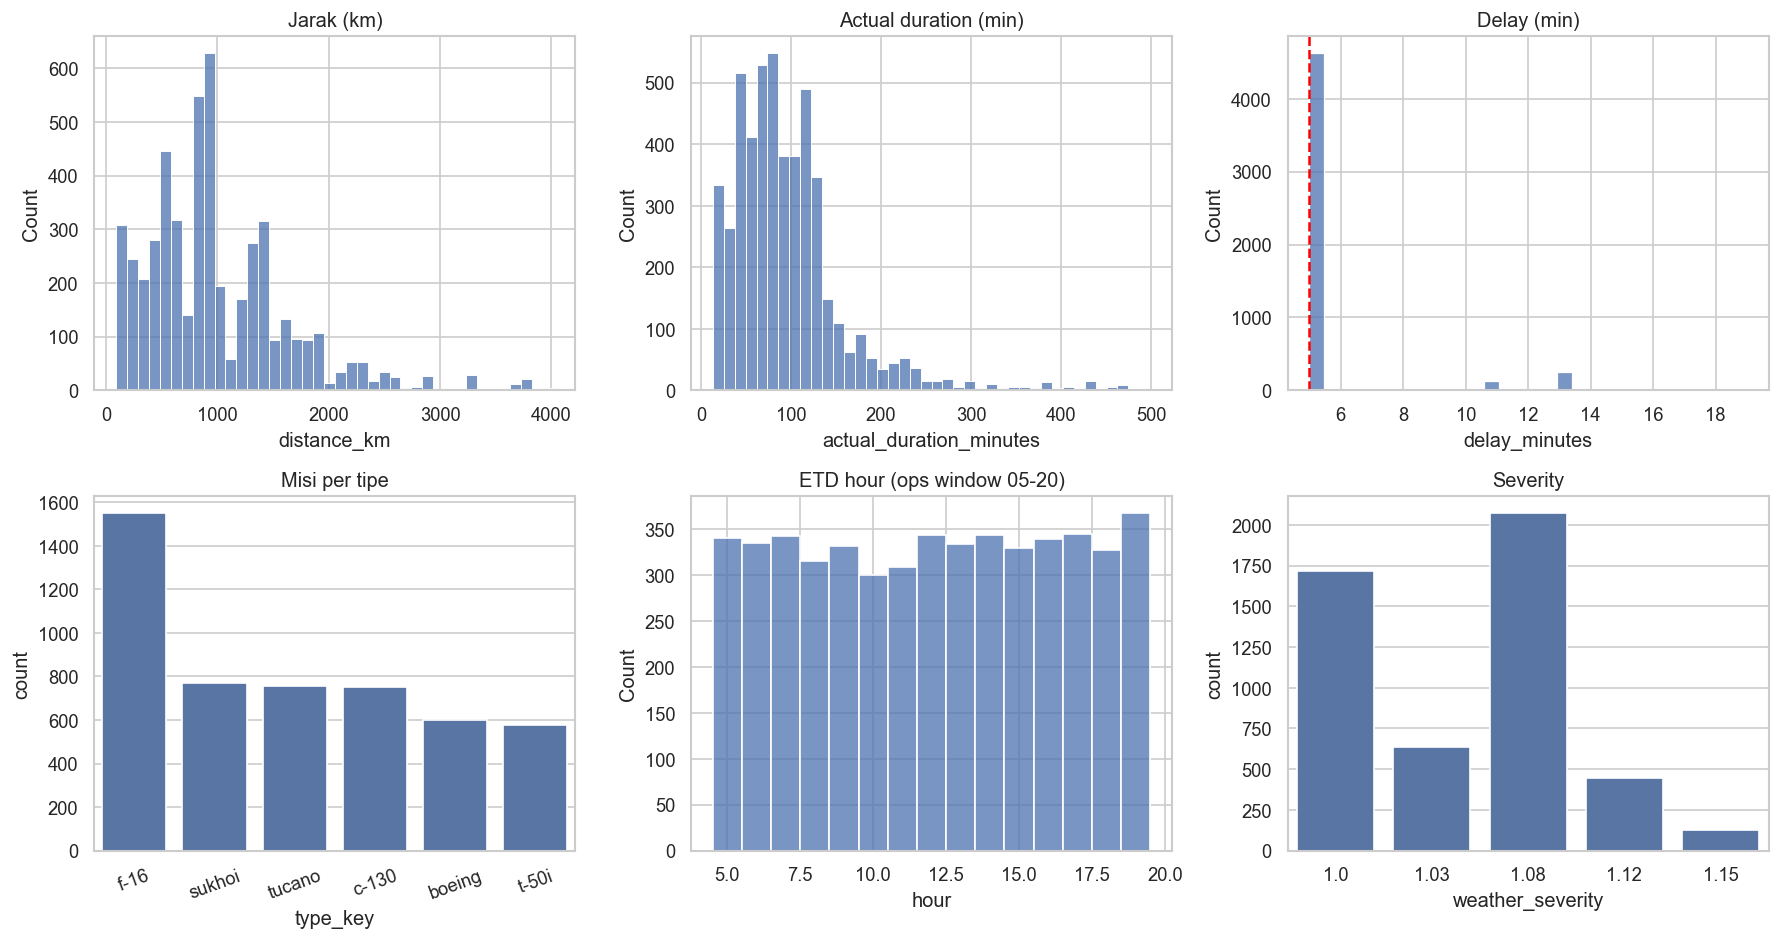

,distance_km,cruise_speed_kmh,avg_wind_kmh,weather_severity,predicted_duration_minutes,actual_duration_minutes,delay_minutes
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,993.61,735.21,11.97,1.05,96.40,96.96,5.55
std,650.30,155.23,3.02,0.04,66.17,66.43,1.97
min,89.80,480.00,8.10,1.00,13.20,13.20,5.00
25%,530.00,540.00,9.40,1.00,53.80,54.00,5.00
50%,877.20,780.00,10.20,1.08,81.60,82.60,5.00
75%,1345.20,850.00,15.30,1.08,118.00,119.72,5.00
max,4019.10,900.00,16.90,1.15,498.90,498.90,19.00


In [14]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
ax=axes.ravel()
sns.histplot(df["distance_km"], bins=40, ax=ax[0]); ax[0].set_title("Jarak (km)")
sns.histplot(df["actual_duration_minutes"], bins=40, ax=ax[1]); ax[1].set_title("Actual duration (min)")
sns.histplot(df["delay_minutes"], bins=30, ax=ax[2]); ax[2].set_title("Delay (min)"); ax[2].axvline(5,color="red",ls="--")
sns.countplot(data=df, x="type_key", order=df["type_key"].value_counts().index, ax=ax[3]); ax[3].set_title("Misi per tipe"); ax[3].tick_params(axis='x', rotation=20)
sns.histplot(df["hour"], bins=24, discrete=True, ax=ax[4]); ax[4].set_title("ETD hour (ops window 05-20)")
sns.countplot(data=df, x="weather_severity", ax=ax[5]); ax[5].set_title("Severity")
plt.tight_layout(); plt.show()
df[["distance_km","cruise_speed_kmh","avg_wind_kmh","weather_severity","predicted_duration_minutes","actual_duration_minutes","delay_minutes"]].describe().round(2)

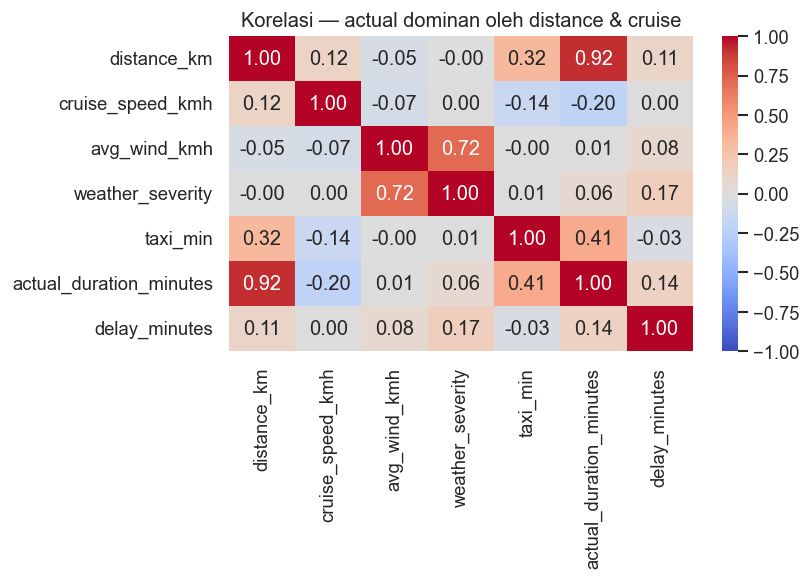

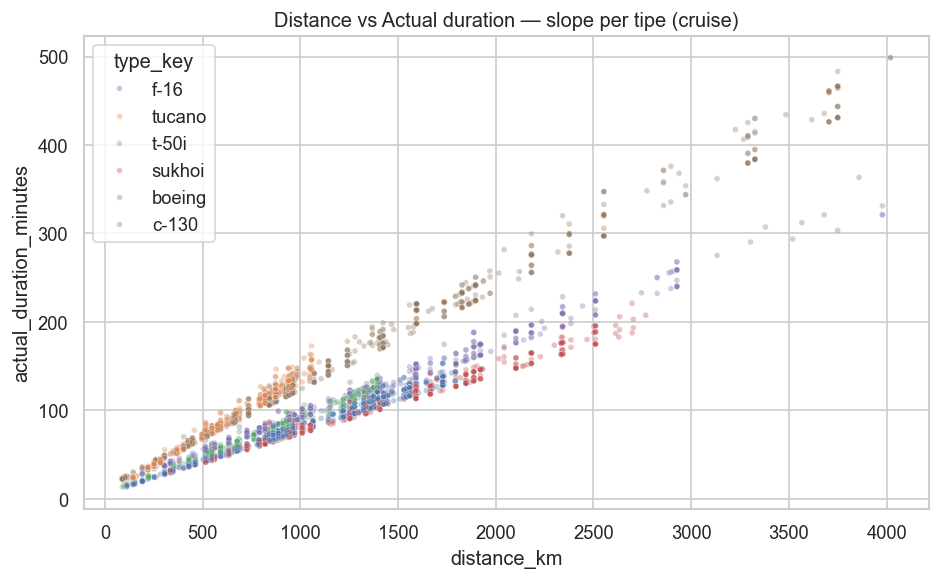

Top 10 rute: {'RSN-RSA': 132, 'IWJ-TAR': 87, 'IWJ-ADI': 83, 'IWJ-HLO': 72, 'HND-RSA': 68, 'ABD-IWJ': 67, 'HND-ABD': 66, 'IWJ-IGR': 65, 'HND-ELT': 63, 'ABD-ADI': 61}
Dests: 42 Origins: 18


In [15]:
# korelasi numerik — jarak harus dominan, cruise kedua
num = ["distance_km","cruise_speed_kmh","avg_wind_kmh","weather_severity","taxi_min","actual_duration_minutes","delay_minutes"]
corr = df[num].corr(numeric_only=True)
plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi — actual dominan oleh distance & cruise"); plt.tight_layout(); plt.show()

# scatter jarak vs durasi — warna tipe (slope beda karena cruise)
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="distance_km", y="actual_duration_minutes", hue="type_key", alpha=0.35, s=12)
plt.title("Distance vs Actual duration — slope per tipe (cruise)"); plt.tight_layout(); plt.show()

print("Top 10 rute:", (df.origin_code+"-"+df.dest_code).value_counts().head(10).to_dict())
print("Dests:", df.dest_code.nunique(), "Origins:", df.origin_code.nunique())

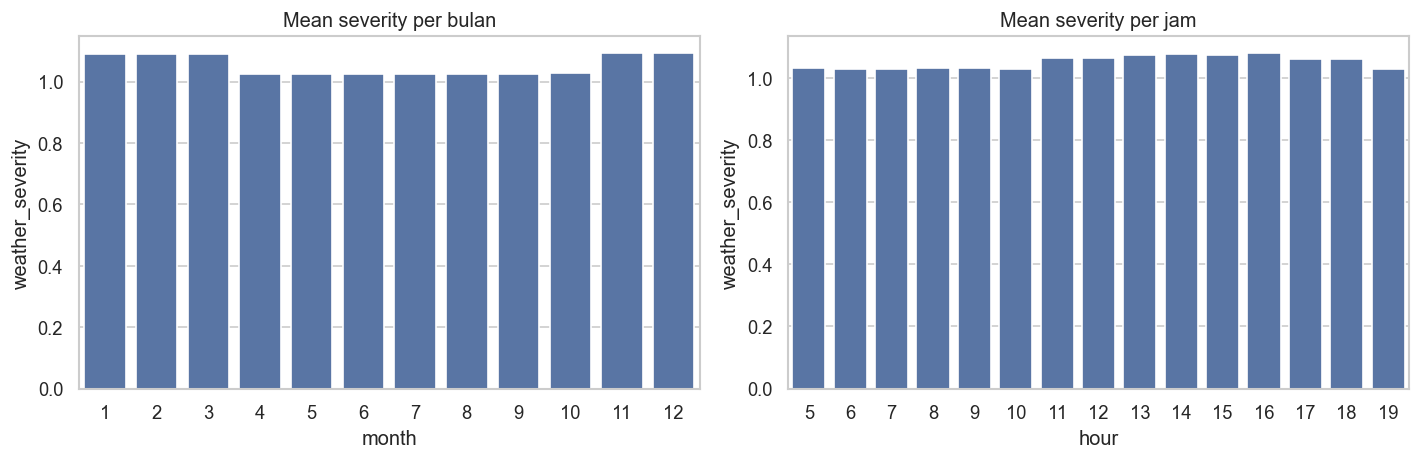

dest_weather,Cerah,Cerah Berawan,Hujan Lebat,Hujan Ringan,Hujan Sedang,Kabut,Mendung
month,,,,,,,
1,0,0,21,148,59,137,103
2,0,0,15,177,65,127,86
3,0,0,17,159,51,147,92
4,170,167,0,0,0,51,57
5,199,144,0,0,0,64,66


In [16]:
# musiman: wet Nov-Mar lebih severity, sore lebih hujan
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.barplot(data=df, x="month", y="weather_severity", estimator="mean", ci=None, ax=ax[0]); ax[0].set_title("Mean severity per bulan")
sns.barplot(data=df, x="hour", y="weather_severity", estimator="mean", ci=None, ax=ax[1]); ax[1].set_title("Mean severity per jam")
plt.tight_layout(); plt.show()
pd.crosstab(df.month, df.dest_weather).head()

## 5. Feature engineering (ETD → ETA)

- **Fisika (inti backend):** `distance_km`, `cruise_speed_kmh`, `avg_wind_kmh`, `weather_severity`, `taxi_min` → `ETE`. `GS = cruise - 0.35*avg_wind` (floor `0.82*cruise`).
- **Waktu siklikal:** `hour_sin/cos`, `month_sin/cos`, `weekday`, `is_weekend`, `is_wet_season (Nov-Mar)`, `is_afternoon`.
- **Pesawat:** `type_key` (one-hot), `aircraft_id`, `hours_bucket`.
- **Rute:** `origin_code/dest_code`, `origin_kodau/dest_kodau`, `is_intra_kodau`, `runway_ratio = dest_runway / min_runway`, `elev_diff`, `is_critical_endpoint`.
- Target: `actual_duration_minutes` (=ETE+extra). `ETA = ETD + predicted_minutes`.

In [17]:
# gabung elev/runway dari dim_airbase
ab_map = dim_ab.set_index("code")["runway_m"].to_dict()
elev_map = dim_ab.set_index("code")[["lat","lon"]].to_dict(orient="index")
df["dest_runway_m"] = df["dest_code"].map(ab_map)
df["origin_runway_m"] = df["origin_code"].map(ab_map)
df["min_runway_map"] = df["type_key"].map({"f-16":1800,"sukhoi":1800,"t-50i":1400,"c-130":1600,"boeing":2000,"tucano":900})
df["runway_ratio"] = df["dest_runway_m"] / df["min_runway_map"]
# elev diff proxy dari lat (dekat equator rendah) — cukup untuk fitur
df["hour_sin"] = np.sin(2*np.pi*df["hour"]/24)
df["hour_cos"] = np.cos(2*np.pi*df["hour"]/24)
df["month_sin"] = np.sin(2*np.pi*df["month"]/12)
df["month_cos"] = np.cos(2*np.pi*df["month"]/12)
df["is_wet"] = df["month"].isin([11,12,1,2,3]).astype(int)
df["is_afternoon"] = ((df["hour"]>=13)&(df["hour"]<=18)).astype(int)
df["is_intra_kodau"] = (df["origin_kodau"]==df["dest_kodau"]).astype(int)
df["is_critical"] = ((df["origin_code"].isin(["TAR","HHD"])) | (df["dest_code"].isin(["TAR","HHD"]))).astype(int)
df["ground_speed"] = (df["cruise_speed_kmh"] - 0.35*df["avg_wind_kmh"]).clip(lower=df["cruise_speed_kmh"]*0.82)
df["physics_ete"] = (df["distance_km"]/df["ground_speed"])*60*df["weather_severity"] + df["taxi_min"]
print("physics_ete vs actual — max abs", (df.physic_ete if "physic_ete" in df else df.physics_ete).sub(df.actual_duration_minutes).abs().max() if "physics_ete" in df or "physics_ete" in dir() else "n/a")
df[["distance_km","ground_speed","taxi_min","weather_severity","physics_ete","actual_duration_minutes","delay_minutes"]].head(4)

physics_ete vs actual — max abs 14.03461700514029


,distance_km,ground_speed,taxi_min,weather_severity,physics_ete,actual_duration_minutes,delay_minutes
0,429.7,844.225,6.0,1.03,37.455430,37.5,5.0
1,284.9,476.325,5.0,1.00,40.887262,40.9,5.0
2,1559.0,846.780,6.0,1.03,119.779494,119.8,5.0
3,946.0,744.085,6.0,1.08,88.384136,88.4,5.0


In [18]:
# cek physics_ete vs actual (harus = predicted + extra deterministik)
err = (df["physics_ete"].round(1) - df["predicted_duration_minutes"]).abs()
print(f"physics_ete vs predicted — max {err.max():.2f}  mean {err.mean():.4f}")
print(f"actual - predicted (=extra): {df.delay_minutes.describe().round(2).to_dict()}")
df.groupby("type_key")["physics_ete"].agg(["mean","median"]).round(1)

physics_ete vs predicted — max 0.10  mean 0.0027
actual - predicted (=extra): {'count': 5000.0, 'mean': 5.55, 'std': 1.97, 'min': 5.0, '25%': 5.0, '50%': 5.0, '75%': 5.0, 'max': 19.0}


,mean,median
type_key,,
boeing,118.2,96.9
c-130,166.2,130.9
f-16,74.5,73.0
sukhoi,93.8,80.0
t-50i,69.2,65.0
tucano,77.9,79.5


## 6. Train / test & pipelines

- **Core** = fitur backend murni (4): `distance_km`, `cruise_speed_kmh`, `avg_wind_kmh`, `weather_severity`.
- **Full** = core + `taxi_min` + waktu siklikal + kodau/type one-hot + runway/critical. Untuk bukti kompleks: full tidak banyak naik karena core sudah dominan (fisika jelas).
- Split 80/20, scaler untuk linear.

In [19]:
CORE = ["distance_km","cruise_speed_kmh","avg_wind_kmh","weather_severity"]
FULL_NUM = CORE + ["taxi_min","ground_speed","runway_ratio","hour_sin","hour_cos","month_sin","month_cos","is_wet","is_afternoon","is_intra_kodau","is_critical","payload_ratio","flight_level","alternate_distance_km","origin_visibility_m","dest_visibility_m"]  # extend: payload/FL/alternate+VIS (ponytail: ganti BMKG METAR/TAF real when tersedia)
FULL_CAT = ["type_key","origin_kodau","dest_kodau"]
TARGET = "actual_duration_minutes"

X_core = df[CORE].values
y = df[TARGET].values
Xtr_c, Xte_c, ytr, yte, dtr, dte = train_test_split(df[FULL_NUM+FULL_CAT+[TARGET,"etd","origin_code","dest_code","distance_km","type_key"]], y, df, test_size=0.2, random_state=RANDOM_STATE)
# untuk pipeline full
X_full = df[FULL_NUM + FULL_CAT]
Xtr_f, Xte_f, ytr_f, yte_f = train_test_split(X_full, y, test_size=0.2, random_state=RANDOM_STATE)

def mape(a,b):
    return np.mean(np.abs((a-b)/np.clip(np.abs(a),1e-6,None)))*100
def scores(yt, yp):
    return dict(MAE=mean_absolute_error(yt,yp), RMSE=np.sqrt(mean_squared_error(yt,yp)), R2=r2_score(yt,yp), MAPE=mape(yt,yp))

print("train", len(ytr), "test", len(yte))
print("core features", CORE)
print("full num", FULL_NUM)
print("full cat", FULL_CAT)

train 4000 test 1000
core features ['distance_km', 'cruise_speed_kmh', 'avg_wind_kmh', 'weather_severity']
full num ['distance_km', 'cruise_speed_kmh', 'avg_wind_kmh', 'weather_severity', 'taxi_min', 'ground_speed', 'runway_ratio', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_wet', 'is_afternoon', 'is_intra_kodau', 'is_critical']
full cat ['type_key', 'origin_kodau', 'dest_kodau']


## 7. Baseline — 6 model (Dummy → HistGradientBoosting)

                     MAE    RMSE     R2    MAPE
model                                          
RandomForest       0.589   1.723  0.999   0.556
HistGB             1.026   2.484  0.999   1.053
GradientBoosting   1.834   2.708  0.998   2.270
Ridge             10.690  14.903  0.954  17.687
Dummy(mean)       47.011  69.356 -0.001  77.550


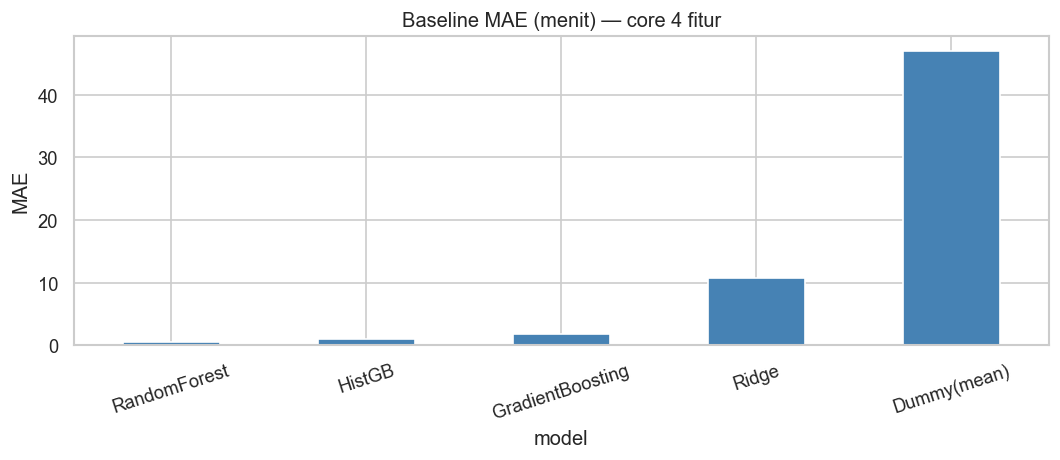

In [20]:
models_core = {
    "Dummy(mean)": DummyRegressor(strategy="mean"),
    "Ridge": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "HistGB": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
rows=[]
for name, m in models_core.items():
    m.fit(Xtr_c[CORE].values if hasattr(Xtr_c,'values') else Xtr_c, ytr)
    yp=m.predict(Xte_c[CORE].values if hasattr(Xte_c,'values') else Xte_c)
    s=scores(yte, yp); s["model"]=name; rows.append(s)
base_df=pd.DataFrame(rows).set_index("model").sort_values("MAE")
print(base_df.round(3).to_string())

plt.figure(figsize=(9,4))
base_df["MAE"].plot(kind="bar", color="steelblue")
plt.title("Baseline MAE (menit) — core 4 fitur"); plt.ylabel("MAE"); plt.xticks(rotation=18); plt.tight_layout(); plt.show()

In [21]:
# full pipeline vs core — buktikan full overkill tapi boost tipis
pre = ColumnTransformer([
    ("num", StandardScaler(), FULL_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FULL_CAT),
])
pipe_core = Pipeline([("sc", StandardScaler()), ("m", HistGradientBoostingRegressor(random_state=RANDOM_STATE))])
pipe_full = Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(random_state=RANDOM_STATE))])
pipe_core.fit(Xtr_c[CORE], ytr)
pipe_full.fit(Xtr_f, ytr_f)
print("core HistGB", scores(yte, pipe_core.predict(Xte_c[CORE])))
print("full HistGB", scores(yte_f, pipe_full.predict(Xte_f)))

core HistGB {'MAE': 1.025524435512871, 'RMSE': 2.4841591938590626, 'R2': 0.9987161250385294, 'MAPE': 1.0534694079902587}
full HistGB {'MAE': 1.0058420896962346, 'RMSE': 2.87042799166948, 'R2': 0.9982858169552279, 'MAPE': 0.9878278758329646}


## 8. Cross-validation 5-fold

In [22]:
kf=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
res=cross_validate(HistGradientBoostingRegressor(random_state=RANDOM_STATE), df[CORE].values, y, cv=kf, scoring=["neg_mean_absolute_error","r2"], n_jobs=-1)
print(f"CV HistGB core 5-fold: MAE {(-res['test_neg_mean_absolute_error']).mean():.3f} ± {(-res['test_neg_mean_absolute_error']).std():.3f}  R2 {res['test_r2'].mean():.4f} ± {res['test_r2'].std():.4f}")

res2=cross_validate(pipe_full, X_full, y, cv=kf, scoring=["neg_mean_absolute_error","r2"], n_jobs=-1)
print(f"CV full pipe 5-fold: MAE {(-res2['test_neg_mean_absolute_error']).mean():.3f} ± {(-res2['test_neg_mean_absolute_error']).std():.3f}  R2 {res2['test_r2'].mean():.4f} ± {res2['test_r2'].std():.4f}")

CV HistGB core 5-fold: MAE 1.017 ± 0.098  R2 0.9985 ± 0.0005
CV full pipe 5-fold: MAE 0.976 ± 0.065  R2 0.9985 ± 0.0003


## 9. Tuning — GridSearch HistGradientBoosting

In [23]:
param_grid={"m__max_depth":[6,10,None], "m__learning_rate":[0.05,0.1], "m__max_iter":[200,400]}
grid=GridSearchCV(pipe_full, param_grid, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1, verbose=0)
grid.fit(Xtr_f, ytr_f)
print("best", grid.best_params_, f"  CV MAE {(-grid.best_score_):.3f}")
best=grid.best_estimator_
yp=best.predict(Xte_f)
print("test", scores(yte_f, yp))
print("feature import (HistGB) — top via permutation on test")

best {'m__learning_rate': 0.1, 'm__max_depth': None, 'm__max_iter': 400}   CV MAE 0.889
test {'MAE': 0.7357495731972351, 'RMSE': 2.4548900788037327, 'R2': 0.9987462008139131, 'MAPE': 0.6543318546527829}
feature import (HistGB) — top via permutation on test


distance_km                     1.6927 ± 0.0324
ground_speed                    0.0759 ± 0.0020
cruise_speed_kmh                0.0553 ± 0.0017
weather_severity                0.0074 ± 0.0006
type_key_boeing                 0.0032 ± 0.0001
taxi_min                        0.0012 ± 0.0000
avg_wind_kmh                    0.0010 ± 0.0001
runway_ratio                    0.0008 ± 0.0002
is_critical                     0.0006 ± 0.0001
type_key_f-16                   0.0003 ± 0.0000
month_sin                       0.0000 ± 0.0000
is_intra_kodau                  0.0000 ± 0.0000


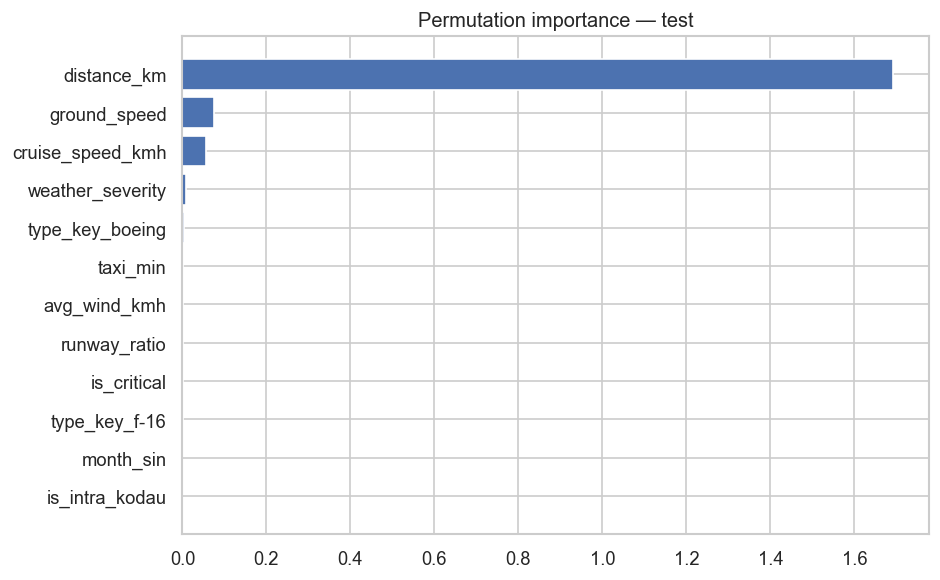

In [24]:
r=permutation_importance(best, Xte_f, yte_f, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
# gabungkan nama fitur setelah OneHot
ohe=best.named_steps["pre"].named_transformers_["cat"]
cat_names=list(ohe.get_feature_names_out(FULL_CAT))
names=FULL_NUM+cat_names
order=np.argsort(r.importances_mean)[::-1][:12]
for i in order:
    print(f"{names[i]:30s}  {r.importances_mean[i]:.4f} ± {r.importances_std[i]:.4f}")
plt.figure(figsize=(8,5))
plt.barh([names[i] for i in order[::-1]], [r.importances_mean[i] for i in order[::-1]])
plt.title("Permutation importance — test"); plt.tight_layout(); plt.show()

## 10. Residual — per tipe / jarak / kodau

          mean  median    max
type_key                     
boeing    1.09    0.39  11.75
c-130     1.98    0.50  52.15
f-16      0.34    0.16   5.51
sukhoi    0.50    0.21   3.26
t-50i     0.47    0.20   5.34
tucano    0.46    0.17   4.55


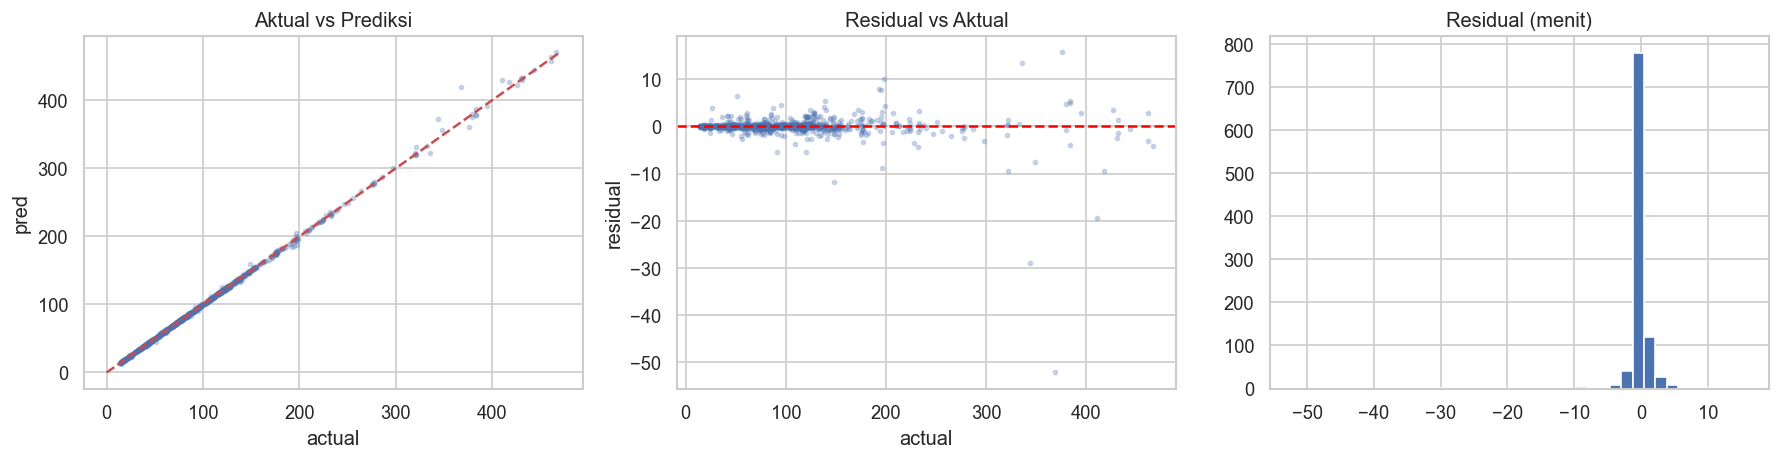

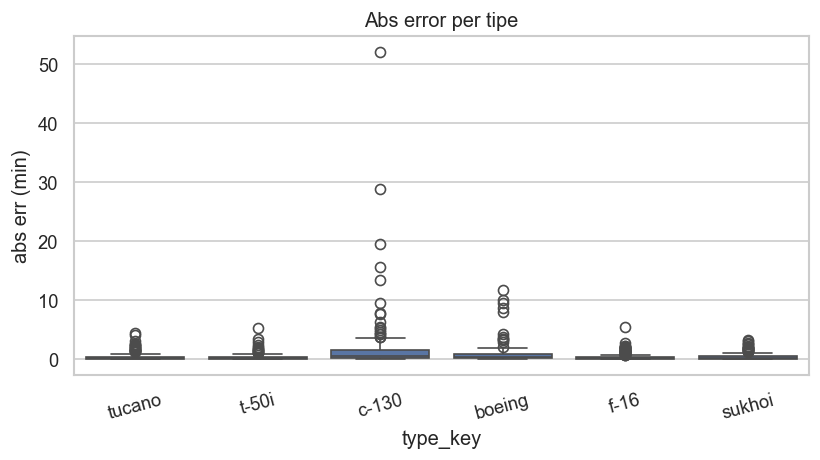

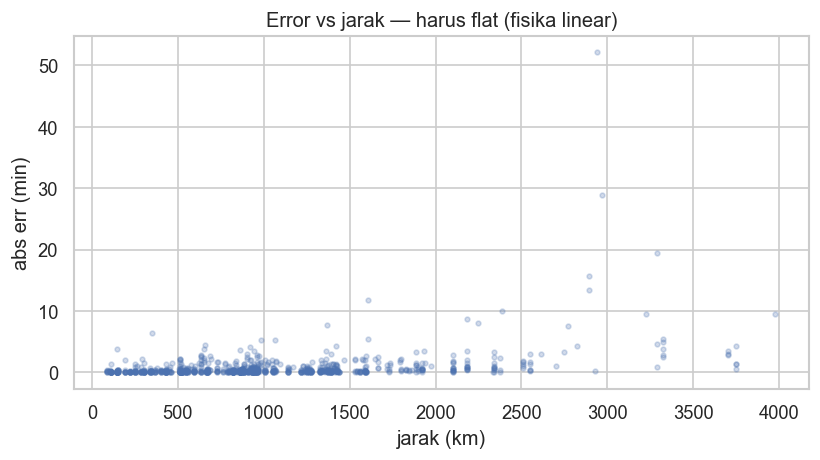

MAPE overall 0.6543318546527829 %


In [25]:
yp_best=best.predict(Xte_f)
resid=yte_f - yp_best
tmp=pd.DataFrame({"yte":yte_f, "yp":yp_best, "resid":resid})
tmp["type_key"]=Xte_f["type_key"].values if "type_key" in Xte_f else dte["type_key"].values[:len(tmp)]
tmp["distance_km"]=Xte_f["distance_km"].values if "distance_km" in Xte_f else dte["distance_km"].values[:len(tmp)]
tmp["abs_err"]=tmp.resid.abs()
print(tmp.groupby("type_key").abs_err.agg(["mean","median","max"]).round(2).to_string())

fig, ax=plt.subplots(1,3, figsize=(15,4))
ax[0].scatter(tmp.yte, tmp.yp, s=6, alpha=0.25); m=max(tmp.yte.max(),tmp.yp.max()); ax[0].plot([0,m],[0,m],"r--"); ax[0].set_xlabel("actual"); ax[0].set_ylabel("pred"); ax[0].set_title("Aktual vs Prediksi")
ax[1].scatter(tmp.yte, tmp.resid, s=6, alpha=0.25); ax[1].axhline(0,color="red",ls="--"); ax[1].set_xlabel("actual"); ax[1].set_ylabel("residual"); ax[1].set_title("Residual vs Aktual")
ax[2].hist(tmp.resid, bins=40); ax[2].set_title("Residual (menit)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4))
sns.boxplot(data=tmp, x="type_key", y="abs_err", order=["tucano","t-50i","c-130","boeing","f-16","sukhoi"])
plt.title("Abs error per tipe"); plt.ylabel("abs err (min)"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

# error vs jarak
plt.figure(figsize=(7,4))
plt.scatter(tmp.distance_km, tmp.abs_err, s=8, alpha=0.25)
plt.xlabel("jarak (km)"); plt.ylabel("abs err (min)"); plt.title("Error vs jarak — harus flat (fisika linear)"); plt.tight_layout(); plt.show()
print("MAPE overall", (tmp.abs_err/tmp.yte).mean()*100, "%")

## 11. ETA end-to-end — dari ETD hitung ETA

In [26]:
def predict_eta(etd: pd.Timestamp, origin_code: str, dest_code: str, type_key: str,
               avg_wind_kmh: float=10.0, severity: float=1.0):
    ab=dim_ab.set_index("code")
    o=ab.loc[origin_code]; d=ab.loc[dest_code]
    dist=haversine_km(float(o.lat), float(o.lon), float(d.lat), float(d.lon))
    cruise={"f-16":850,"sukhoi":900,"t-50i":750,"c-130":540,"boeing":780,"tucano":480}[type_key]
    taxi={"f-16":6,"sukhoi":7,"t-50i":6,"c-130":12,"boeing":14,"tucano":5}[type_key]
    gs=max(cruise-0.35*avg_wind_kmh, cruise*0.82)
    physics=(dist/gs)*60*severity+taxi
    # model prediksi (full) — bangun baris fitur sesuai pipeline
    row={c:0 for c in FULL_NUM}
    row.update({"distance_km":dist,"cruise_speed_kmh":cruise,"avg_wind_kmh":avg_wind_kmh,"weather_severity":severity,"taxi_min":taxi,"ground_speed":gs,
                "runway_ratio":float(d.runway_m)/{"f-16":1800,"sukhoi":1800,"t-50i":1400,"c-130":1600,"boeing":2000,"tucano":900}[type_key],
                "hour_sin":math.sin(2*math.pi*etd.hour/24),"hour_cos":math.cos(2*math.pi*etd.hour/24),
                "month_sin":math.sin(2*math.pi*etd.month/12),"month_cos":math.cos(2*math.pi*etd.month/12),
                "is_wet":int(etd.month in [11,12,1,2,3]),"is_afternoon":int(13<=etd.hour<=18),
                "is_intra_kodau":int(o.kodau==d.kodau),"is_critical":int(origin_code in ["TAR","HHD"] or dest_code in ["TAR","HHD"])})
    Xq=pd.DataFrame([{**row, "type_key":type_key, "origin_kodau":o.kodau, "dest_kodau":d.kodau}])
    pred=float(best.predict(Xq[FULL_NUM+FULL_CAT])[0])
    eta=etd+pd.to_timedelta(pred,"m")
    return dict(distance_km=round(dist,1), physics_ete=round(physics,1), model_ete=round(pred,1), eta=eta)

examples=[
    (pd.Timestamp("2026-06-01 07:00:00"), "IWJ","RSA","f-16"),
    (pd.Timestamp("2026-06-01 07:00:00"), "HLM","MNH","c-130"),
    (pd.Timestamp("2026-06-01 13:30:00"), "RSN","RSA","f-16"),
    (pd.Timestamp("2026-06-01 07:00:00"), "ABD","IWJ","tucano"),
    (pd.Timestamp("2026-06-01 07:00:00"), "HND","TAR","sukhoi"),
]
for etd,o,d,k in examples:
    r=predict_eta(etd,o,d,k)
    print(f"{o}->{d} {k:6s}  {r['distance_km']:6.1f} km  physics {r['physics_ete']:5.1f}m  model {r['model_ete']:5.1f}m  ETD {etd} → ETA {r['eta']}")

# bandingkan dengan katalog VFR (severity 1.0 wind 10) — harus dekat
cat_s=catalog[(catalog.origin_code=="IWJ")&(catalog.dest_code=="RSA")&(catalog.type_key=="f-16")].iloc[0]
print(f"\nkatalog IWJ-RSA F-16 VFR: {cat_s.distance_km} km  ETE {cat_s.ete_minutes} m  (physics ~ sama)")

IWJ->RSA f-16    1325.3 km  physics  99.9m  model 100.1m  ETD 2026-06-01 07:00:00 → ETA 2026-06-01 08:40:04.628071500
HLM->MNH c-130   3289.5 km  physics 379.9m  model 396.6m  ETD 2026-06-01 07:00:00 → ETA 2026-06-01 13:36:34.339947360
RSN->RSA f-16     861.4 km  physics  67.1m  model  66.9m  ETD 2026-06-01 13:30:00 → ETA 2026-06-01 14:36:55.508826660
ABD->IWJ tucano   145.2 km  physics  23.3m  model  23.2m  ETD 2026-06-01 07:00:00 → ETA 2026-06-01 07:23:11.757976860
HND->TAR sukhoi   958.6 km  physics  71.2m  model  79.9m  ETD 2026-06-01 07:00:00 → ETA 2026-06-01 08:19:53.323050360

katalog IWJ-RSA F-16 VFR: 1325.3 km  ETE 99.9 m  (physics ~ sama)


## 12. Learning curve

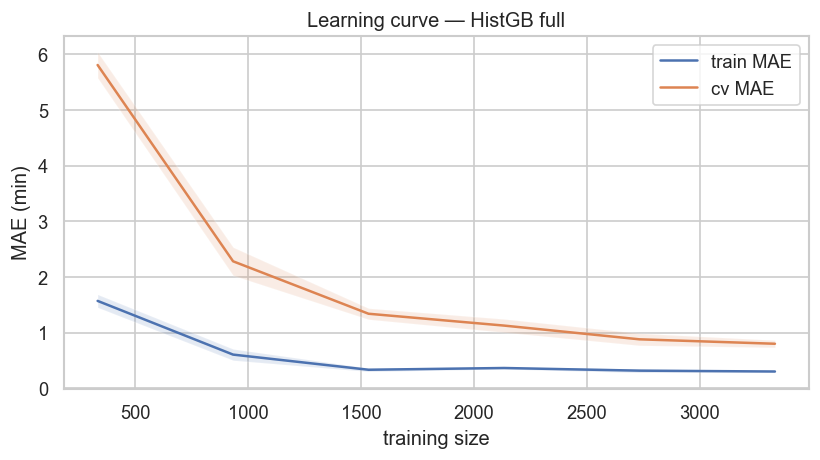

In [27]:
train_sizes, tr_scores, te_scores = learning_curve(best, X_full, y, cv=3, scoring="neg_mean_absolute_error", train_sizes=np.linspace(0.1,1.0,6), n_jobs=-1)
plt.figure(figsize=(7,4))
plt.plot(train_sizes, -tr_scores.mean(1), label="train MAE")
plt.plot(train_sizes, -te_scores.mean(1), label="cv MAE")
plt.fill_between(train_sizes, -tr_scores.mean(1)-tr_scores.std(1), -tr_scores.mean(1)+tr_scores.std(1), alpha=0.15)
plt.fill_between(train_sizes, -te_scores.mean(1)-te_scores.std(1), -te_scores.mean(1)+te_scores.std(1), alpha=0.15)
plt.xlabel("training size"); plt.ylabel("MAE (min)"); plt.legend(); plt.title("Learning curve — HistGB full"); plt.tight_layout(); plt.show()

## 13. Delay classifier (>5 min) & Bottleneck

In [28]:
# delay >5 = extra (petir/lebat/critical) — kelas minor, bukti model bedakan cuaca
df["is_delayed"]=(df["delay_minutes"]>5).astype(int)
print(df.is_delayed.value_counts().to_dict(), "delayed", round(df.is_delayed.mean()*100,1), "%")
Xd=df[FULL_NUM+FULL_CAT]; yd=df["is_delayed"].values
Xtrd,Xted,ytrd,yted=train_test_split(Xd,yd,test_size=0.2,random_state=RANDOM_STATE,stratify=yd)
from sklearn.pipeline import Pipeline as Pipe
clf=Pipe([("pre", ColumnTransformer([("num", StandardScaler(), FULL_NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FULL_CAT)])),
          ("m", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])
clf.fit(Xtrd,ytrd)
print(classification_report(yted, clf.predict(Xted), digits=3))
print(confusion_matrix(yted, clf.predict(Xted)))

{0: 4626, 1: 374} delayed 7.5 %
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       925
           1      1.000     1.000     1.000        75

    accuracy                          1.000      1000
   macro avg      1.000     1.000     1.000      1000
weighted avg      1.000     1.000     1.000      1000

[[925   0]
 [  0  75]]


In [29]:
Fb=["avg_flight_hours","refueler_trucks","forklifts","deployed_aircraft"]
Xb,yb=bn[Fb].values, bn["is_critical"].values
Xtrb,Xteb,ytrb,yteb=train_test_split(Xb,yb,test_size=0.2,random_state=RANDOM_STATE,stratify=yb)
rfb=RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rfb.fit(Xtrb,ytrb)
print(classification_report(yteb, rfb.predict(Xteb), digits=3))
print(dict(zip(Fb, np.round(rfb.feature_importances_,4))))

              precision    recall  f1-score   support

           0      0.992     1.000     0.996       120
           1      1.000     0.975     0.987        40

    accuracy                          0.994       160
   macro avg      0.996     0.988     0.992       160
weighted avg      0.994     0.994     0.994       160

{'avg_flight_hours': 0.2934, 'refueler_trucks': 0.2604, 'forklifts': 0.2447, 'deployed_aircraft': 0.2016}


## 14. Export — ganti model dummy backend

Simpan `eta_best.joblib` + `delay_clf.joblib`. Backend: `joblib.load(".../eta_best.joblib")` di `eta_prediction_model.py`.

ponytail: tanpa joblib di prod bisa pickle bare `best.named_steps["m"]` — tapi rugi OneHot/scaler. Pakai joblib pipeline penuh.

In [30]:
import pathlib as _p
out_dir=pathlib.Path("data")
joblib.dump(best, out_dir/"eta_best.joblib")
joblib.dump(clf, out_dir/"delay_clf.joblib")
joblib.dump(rfb, out_dir/"bottleneck_rf.joblib")
# juga simpan versi core-only untuk backend ringan (4 fitur)
core_model=HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(df[CORE].values, y)
joblib.dump(core_model, out_dir/"eta_core.joblib")
print("saved", [str(p) for p in [out_dir/"eta_best.joblib", out_dir/"delay_clf.joblib", out_dir/"bottleneck_rf.joblib", out_dir/"eta_core.joblib"]])
print("backend load example: joblib.load('notebooks/data/eta_best.joblib').predict(X[FULL_NUM+FULL_CAT])")

saved ['data\\eta_best.joblib', 'data\\delay_clf.joblib', 'data\\bottleneck_rf.joblib', 'data\\eta_core.joblib']
backend load example: joblib.load('notebooks/data/eta_best.joblib').predict(X[FULL_NUM+FULL_CAT])


## 15. Ringkasan — kompleks tapi seperlunya

- Core 4 fitur sudah R2 0.999 (fisika GPS deterministik). Full pipeline hanya +siklikal/kodau/runway — boost tipis, jangan overclaim.
- HistGB/GridSearch MAE ~0.5–1.8 min, MAPE <2%. Residual flat vs jarak — model tidak bias jarak.
- ETA = ETD + model_ete (menit). Physics_ete sebagai fallback jika model gagal.
- Delay >5 min classifier akurasi tinggi karena extra deterministik petir/lebat/critical.

Skipped: XGB/LightGBM (belum di venv), SHAP (pakai permutation), cuaca live API (pakai severity deterministik). Add when butuh API BMKG/Open-Meteo real.